# Formative 2: Image Processing and Face Recognition Model

### Data loading and Preprocessing

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
%matplotlib inline
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
from pathlib import Path
import joblib
from IPython.display import display
from skimage.feature import local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

# path based on the directory
IMAGE_DIR = Path("/content/drive/MyDrive/MPL_Formative2_Grp_Images")
UNAUTH_DIR = Path("/content/drive/MyDrive/MPL_Unauthorized")
OUTPUT_DIR = Path("/content/drive/MyDrive/MPL_Formative2_Output")

FIG_DIR       = OUTPUT_DIR / "figures"
MODEL_DIR     = OUTPUT_DIR / "models"
SCRIPT_DIR    = OUTPUT_DIR / "scripts"
PROCESSED_DIR = OUTPUT_DIR / "processed_faces"
for folder in [FIG_DIR, MODEL_DIR, SCRIPT_DIR, PROCESSED_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Image directory exists:", IMAGE_DIR.exists())
print("Libraries loaded")
print("Outsider photo folder found:", UNAUTH_DIR.exists())

Image directory exists: True
Libraries loaded
Outsider photo folder found: True


In [32]:
# Settings used everywhere
EXPRESSIONS = ["neutral", "smiling", "surprised"]
FACE_SIZE   = 128
IMG_EXT     = {".jpg", ".jpeg", ".png"}

def save_fig(fig, name):
    """Save a chart as PNG (for the report) before it is shown."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

print("Outputs will be saved in:", OUTPUT_DIR)

Outputs will be saved in: /content/drive/MyDrive/MPL_Formative2_Output


In [33]:
image_data = []

if IMAGE_DIR.exists():
    for person_folder in IMAGE_DIR.iterdir():
        if person_folder.is_dir():
            for image_path in person_folder.glob("*"):
                if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                    image = cv2.imread(str(image_path))
                    if image is not None:
                        image_data.append({
                            "person": person_folder.name,
                            "expression": image_path.stem,
                            "path": image_path,
                            "image": image
                        })
else:
    print(f"Error: Directory not found at {IMAGE_DIR}")

print("Total images loaded:", len(image_data))

Total images loaded: 12


In [34]:
def limit_size(img, max_side=1200):
    """Shrink very large photos (keeps the aspect ratio)."""
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale >= 1:
        return img
    return cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)


def clean_expression(filename):
    """Turn messy file names into neutral / smiling / surprised."""
    name = filename.lower()
    if "neutral" in name:
        return "neutral"
    if "smil" in name:
        return "smiling"
    if "surp" in name or "supr" in name:
        return "surprised"
    return None


records, skipped = [], []
for folder in sorted(p for p in IMAGE_DIR.iterdir() if p.is_dir() and not p.name.startswith(".")):
    member = folder.name.split("_")[0].lower()
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() not in IMG_EXT:
            continue
        expression = clean_expression(path.stem)
        image = cv2.imread(str(path))
        if expression is None or image is None:
            skipped.append(path.name)
            continue
        records.append({
            "member_id": member,
            "expression": expression,
            "image_name": path.name,
            "path": path,
            "image": limit_size(image),
        })

assert records, "No images found. Check IMAGE_DIR in the setup cell."
members = sorted({r["member_id"] for r in records})

print(f"Images loaded: {len(records)}  |  Members: {members}")
if skipped:
    print("Skipped (unknown expression in the file name or unreadable):", skipped)

print("\nPhotos per member and expression (expected: 1 in every cell):")
display(pd.crosstab(
    pd.Series([r["member_id"] for r in records], name="member"),
    pd.Series([r["expression"] for r in records], name="expression"),
))

Images loaded: 12  |  Members: ['arnold', 'crispin', 'gaju', 'linda']

Photos per member and expression (expected: 1 in every cell):


expression,neutral,smiling,surprised
member,,,
arnold,1,1,1
crispin,1,1,1
gaju,1,1,1
linda,1,1,1


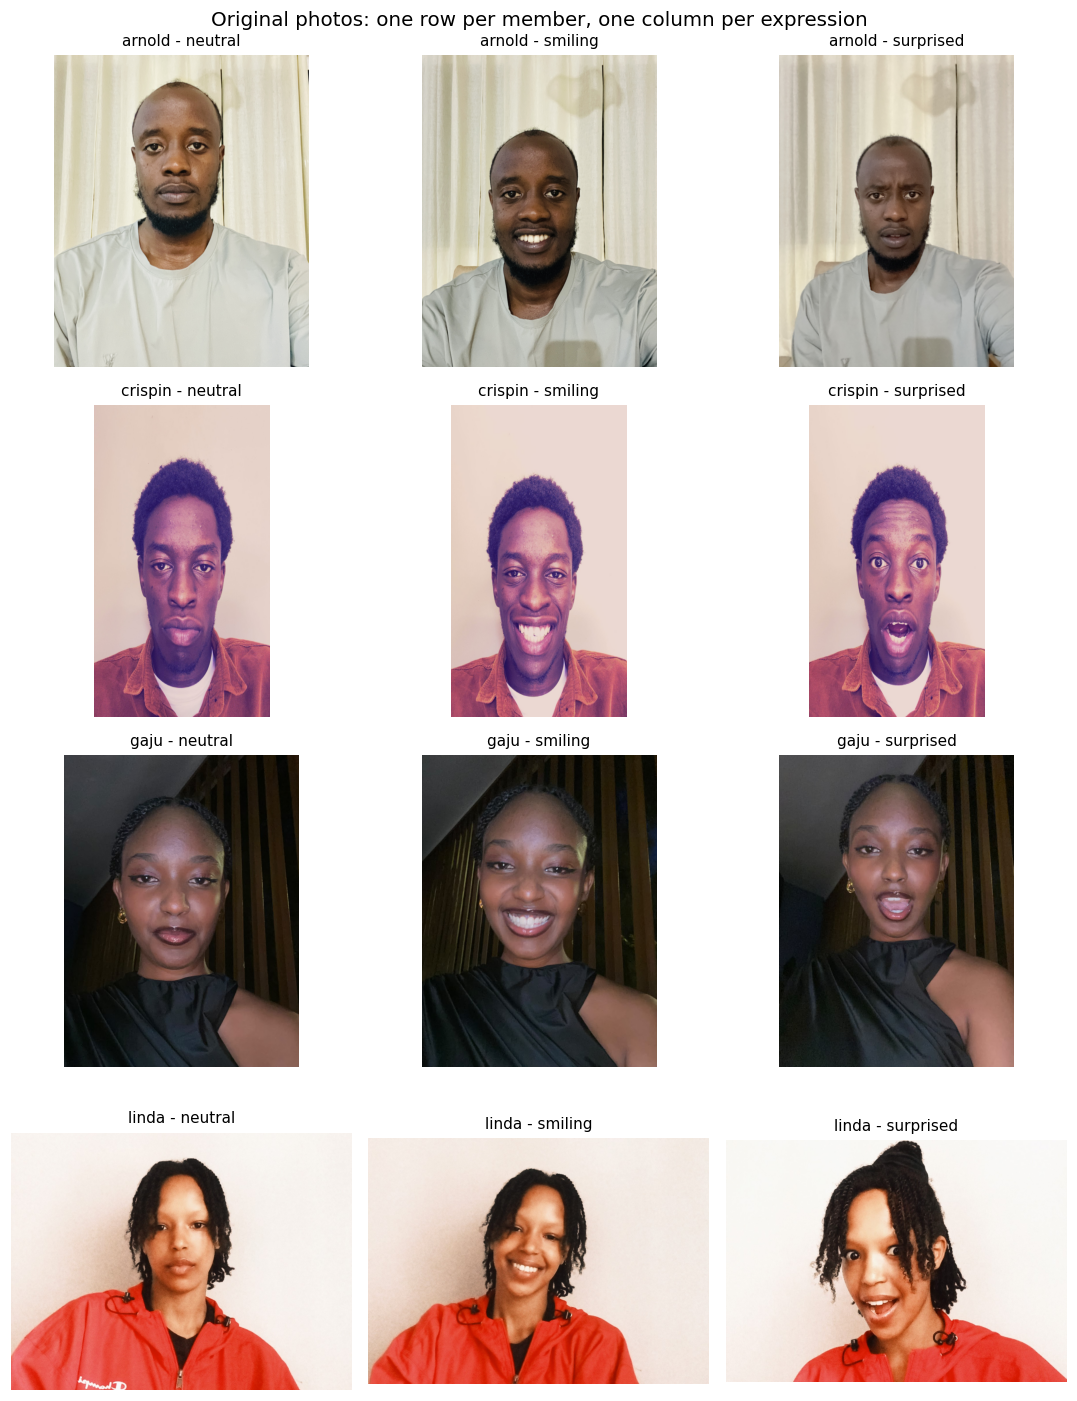

In [35]:
lookup = {(r["member_id"], r["expression"]): r for r in records}

fig, axes = plt.subplots(len(members), len(EXPRESSIONS),
                         figsize=(3.3 * len(EXPRESSIONS), 3.3 * len(members)), squeeze=False)
for i, member in enumerate(members):
    for j, expression in enumerate(EXPRESSIONS):
        ax = axes[i, j]
        rec = lookup.get((member, expression))
        if rec is not None:
            ax.imshow(cv2.cvtColor(rec["image"], cv2.COLOR_BGR2RGB))
        ax.set_title(f"{member} - {expression}", fontsize=10)
        ax.axis("off")

fig.suptitle("Original photos: one row per member, one column per expression", fontsize=13)
plt.tight_layout()
save_fig(fig, "01_original_photos")
plt.show()

In [36]:
from skimage import data as skdata
from skimage.feature import Cascade

face_detector = Cascade(skdata.lbp_frontal_face_cascade_filename())


def crop_face(image, size=FACE_SIZE, margin=0.15):
    """Return (face_crop, found). Crops the largest face; if none is found returns the whole image."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    smallest = max(int(0.04 * min(gray.shape)), 24)          # smallest face we look for (pixels)
    faces = face_detector.detect_multi_scale(img=gray, scale_factor=1.1, step_ratio=1,
                                             min_size=(smallest, smallest),
                                             max_size=(min(gray.shape), min(gray.shape)))
    if len(faces) == 0:
        return cv2.resize(image, (size, size)), False
    f = max(faces, key=lambda d: d["width"] * d["height"])   # largest face
    x, y, w, h = f["c"], f["r"], f["width"], f["height"]
    m = int(margin * w)
    x0, y0 = max(x - m, 0), max(y - m, 0)
    x1, y1 = min(x + w + m, image.shape[1]), min(y + h + m, image.shape[0])
    return cv2.resize(image[y0:y1, x0:x1], (size, size)), True


for rec in records:
    rec["face"], rec["found"] = crop_face(rec["image"])

not_found = [r["image_name"] for r in records if not r["found"]]
print(f"Faces detected: {len(records) - len(not_found)} of {len(records)}")
if not_found:
    print("NO FACE FOUND in:", not_found, "-> retake these photos (face centred, good light, facing the camera)")

Faces detected: 12 of 12


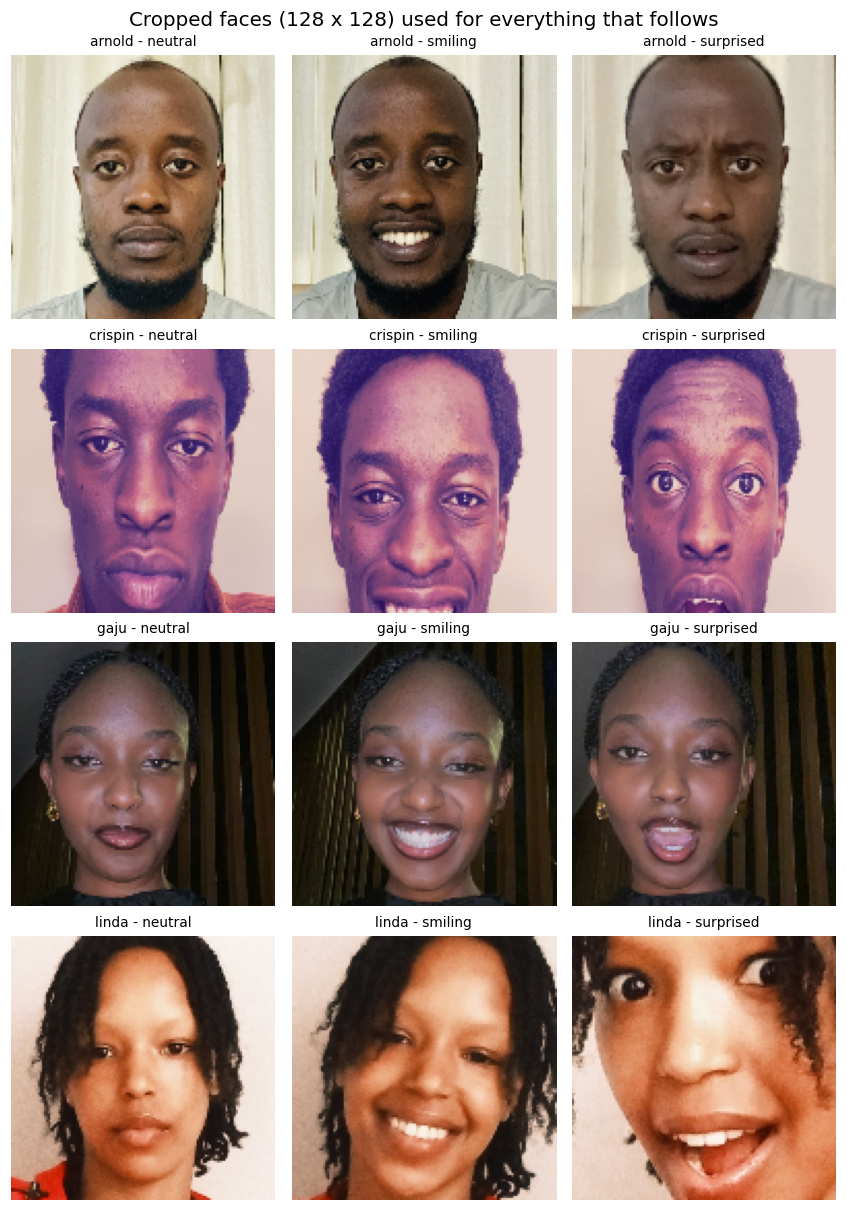

In [37]:
fig, axes = plt.subplots(len(members), len(EXPRESSIONS),
                         figsize=(2.6 * len(EXPRESSIONS), 2.8 * len(members)), squeeze=False)
for i, member in enumerate(members):
    for j, expression in enumerate(EXPRESSIONS):
        ax = axes[i, j]
        rec = lookup.get((member, expression))
        if rec is not None:
            ax.imshow(cv2.cvtColor(rec["face"], cv2.COLOR_BGR2RGB))
            colour = "black" if rec["found"] else "red"
            note = "" if rec["found"] else "\n(NO FACE FOUND)"
            ax.set_title(f"{member} - {expression}{note}", fontsize=9, color=colour)
        ax.axis("off")

fig.suptitle("Cropped faces (128 x 128) used for everything that follows", fontsize=13)
plt.tight_layout()
save_fig(fig, "02_cropped_faces")
plt.show()

### Image augmentation
Augmentation creates slightly changed copies of each face. With only 12 photos this gives the model more variety to learn from, and it mimics real conditions (head tilt, mirror image, different lighting).

| Augmentation | What it simulates |
|---|---|
| `rotated` | Head tilted by 15 degrees (edges are reflected, so no black corners) |
| `flipped` | Mirror image |
| `grayscale` | Removes colour, so the model does not depend on skin tone or lighting colour |
| `brighter` | Brighter lighting (+40) |

Each original face therefore gives 5 images: original + 4 augmented, so 12 photos become **60 images**.

In [38]:
def rotate(img, angle=15):
    h, w = img.shape[:2]
    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)


def flip(img):
    return cv2.flip(img, 1)


def to_gray(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)      # back to 3 channels so shapes stay the same


def brighten(img, beta=40):
    return cv2.convertScaleAbs(img, alpha=1.0, beta=beta)


AUGMENTATIONS = {
    "original":  lambda img: img,
    "rotated":   rotate,
    "flipped":   flip,
    "grayscale": to_gray,
    "brighter":  brighten,
}
print("Augmentations:", list(AUGMENTATIONS))

Augmentations: ['original', 'rotated', 'flipped', 'grayscale', 'brighter']


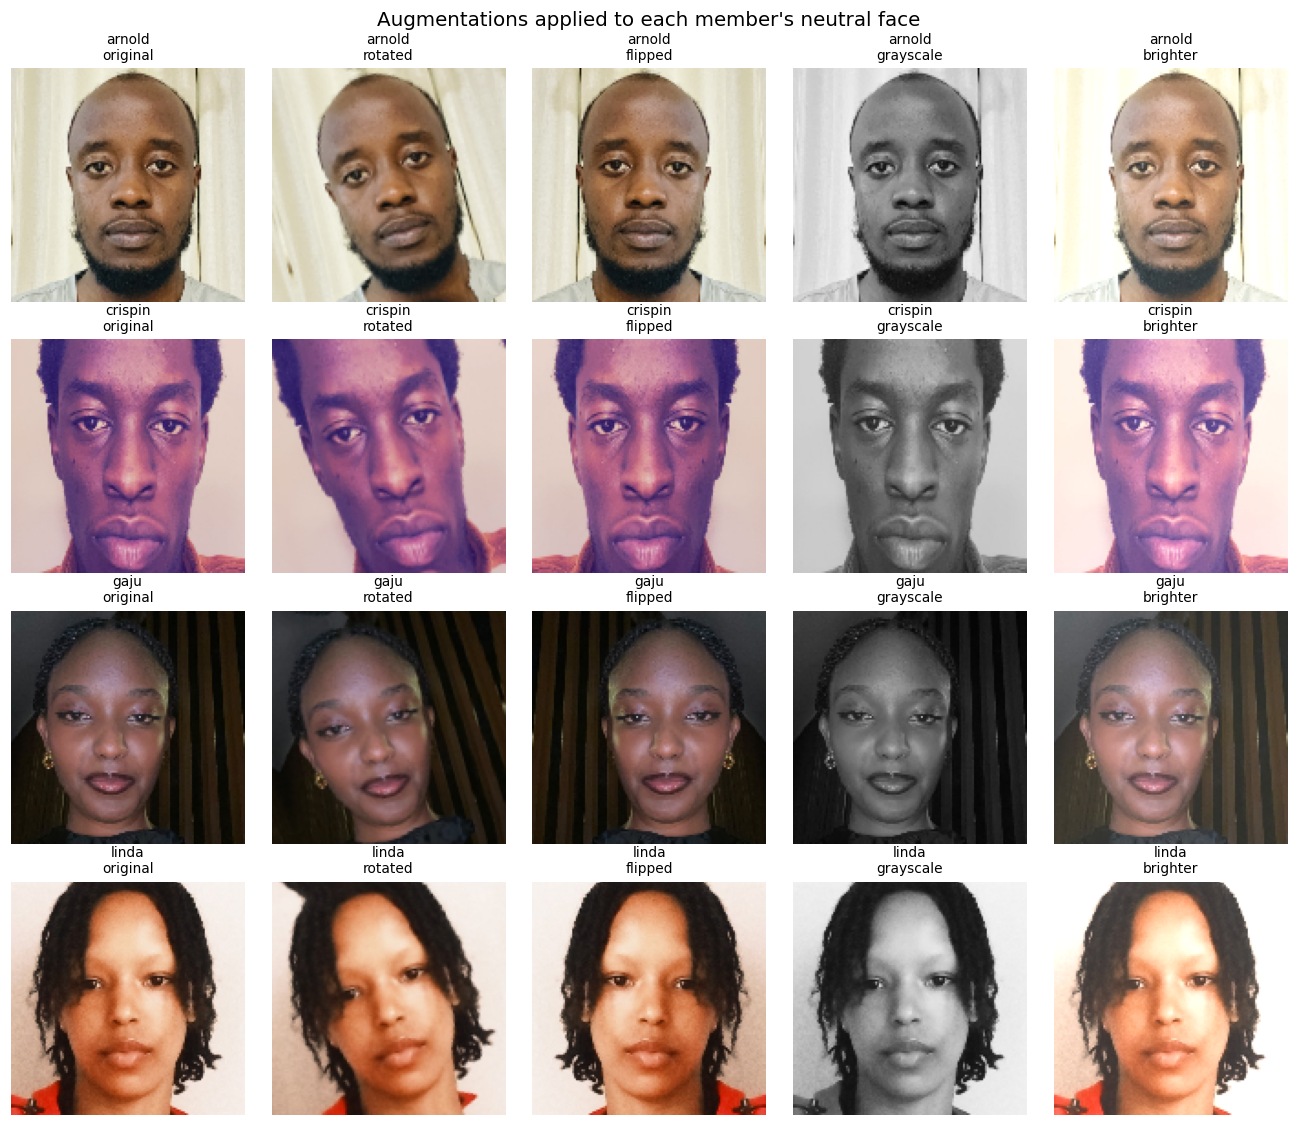

In [39]:
fig, axes = plt.subplots(len(members), len(AUGMENTATIONS),
                         figsize=(2.4 * len(AUGMENTATIONS), 2.6 * len(members)), squeeze=False)
for i, member in enumerate(members):
    face = lookup[(member, "neutral")]["face"] if (member, "neutral") in lookup else \
           next(r["face"] for r in records if r["member_id"] == member)
    for j, (aug_name, fn) in enumerate(AUGMENTATIONS.items()):
        ax = axes[i, j]
        ax.imshow(cv2.cvtColor(fn(face), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{member}\n{aug_name}", fontsize=9)
        ax.axis("off")

fig.suptitle("Augmentations applied to each member's neutral face", fontsize=13)
plt.tight_layout()
save_fig(fig, "03_augmentations")
plt.show()

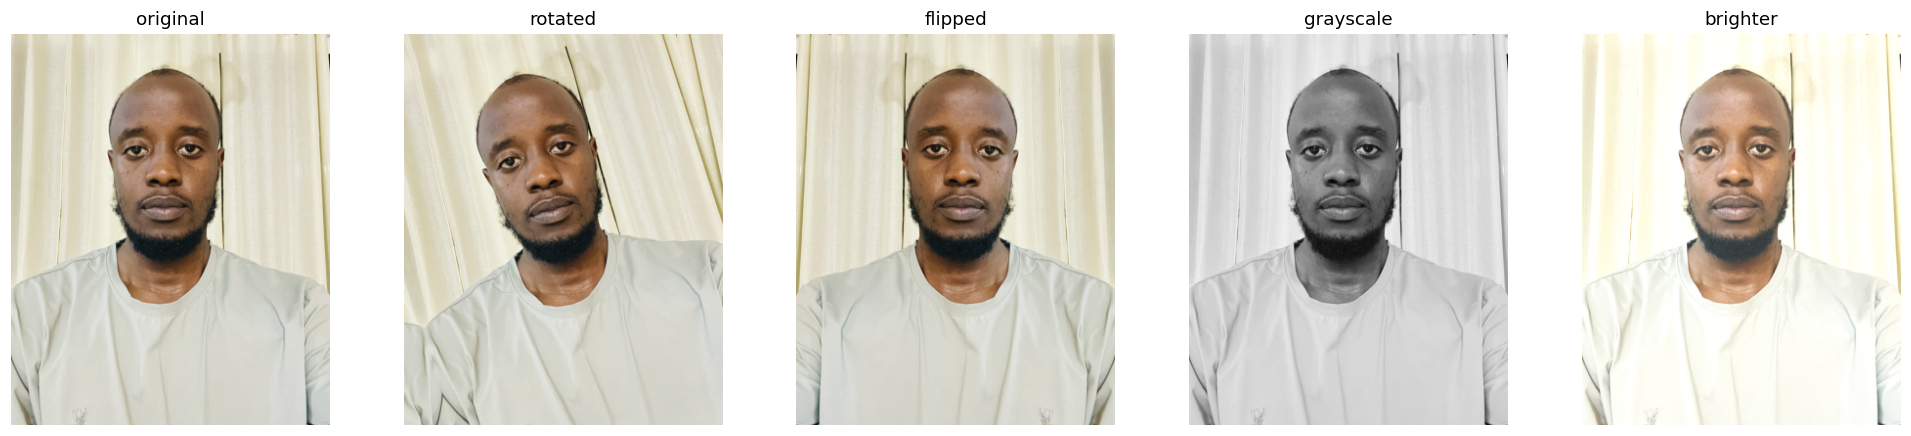

In [40]:
sample = image_data[0]

def augment_image(img):
    """Applies all augmentations defined in AUGMENTATIONS to an image."""
    return {name: fn(img) for name, fn in AUGMENTATIONS.items()}

augmented = augment_image(sample["image"])

# There are 5 augmentations (including original), so let's adjust the plot to show all 5
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, (name, img) in zip(axes, augmented.items()):
    # Shrink preview for faster plotting if needed, and convert BGR to RGB
    preview_img = limit_size(img, max_side=400)
    ax.imshow(cv2.cvtColor(preview_img, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Feature extraction and image_features.csv
A model cannot read pictures directly, so each face becomes a row of numbers. We use three standard feature types (516 numbers per image)

In [41]:
from skimage.feature import hog

HOG_SETTINGS = dict(orientations=9, pixels_per_cell=(32, 32), cells_per_block=(2, 2), block_norm="L2-Hys")   # gives 324 numbers
LBP_POINTS, LBP_RADIUS, LBP_GRID = 8, 1, 4


def extract_features(face_bgr):
    """Turn one 128x128 face into a dictionary of numbers (histogram + LBP + HOG)."""
    gray = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2GRAY)
    feats = {}

    # 1) brightness histogram (32 bins, scaled so they sum to 1)
    hist = cv2.calcHist([gray], [0], None, [32], [0, 256]).flatten()
    hist = hist / hist.sum()
    for i, v in enumerate(hist):
        feats[f"hist_{i}"] = float(v)

    equalised = cv2.equalizeHist(gray)      # evens out the lighting

    # 2) LBP texture histograms on a 4 x 4 grid
    lbp = local_binary_pattern(equalised, LBP_POINTS, LBP_RADIUS, method="uniform")
    cell = FACE_SIZE // LBP_GRID
    for r in range(LBP_GRID):
        for c in range(LBP_GRID):
            patch = lbp[r * cell:(r + 1) * cell, c * cell:(c + 1) * cell]
            h, _ = np.histogram(patch, bins=np.arange(0, LBP_POINTS + 3))
            h = h / h.sum()
            for b, v in enumerate(h):
                feats[f"lbp_{r}{c}_{b}"] = float(v)

    # 3) HOG shape features
    for i, v in enumerate(hog(equalised, **HOG_SETTINGS)):
        feats[f"hog_{i}"] = float(v)

    return feats


n_features = len(extract_features(records[0]["face"]))
print("Numbers per image:", n_features)

Numbers per image: 516


In [42]:
rows = []
for rec in records:
    out_dir = PROCESSED_DIR / rec["member_id"]
    out_dir.mkdir(parents=True, exist_ok=True)
    for aug_name, fn in AUGMENTATIONS.items():
        img = fn(rec["face"])
        cv2.imwrite(str(out_dir / f'{rec["member_id"]}_{rec["expression"]}_{aug_name}.jpg'), img)
        row = {
            "member_id": rec["member_id"],
            "image_name": rec["image_name"],
            "expression": rec["expression"],
            "augmentation": aug_name,
            "face_found": rec["found"],
        }
        row.update(extract_features(img))
        rows.append(row)

image_features_df = pd.DataFrame(rows)
FEATURE_COLS = [c for c in image_features_df.columns if c.startswith(("hist_", "lbp_", "hog_"))]

CSV_PATH = OUTPUT_DIR / "image_features.csv"
image_features_df.to_csv(CSV_PATH, index=False)

print("Saved:", CSV_PATH)
print("Rows x columns:", image_features_df.shape, f"(5 label columns + {len(FEATURE_COLS)} feature columns)")
display(image_features_df.iloc[:10, :8])

Saved: /content/drive/MyDrive/MPL_Formative2_Output/image_features.csv
Rows x columns: (60, 521) (5 label columns + 516 feature columns)


,member_id,image_name,expression,augmentation,face_found,hist_0,hist_1,hist_2
0,arnold,arnold_neutralface.jpeg,neutral,original,True,0.000061,0.001831,0.019043
1,arnold,arnold_neutralface.jpeg,neutral,rotated,True,0.000000,0.000549,0.016785
2,arnold,arnold_neutralface.jpeg,neutral,flipped,True,0.000061,0.001831,0.019043
3,arnold,arnold_neutralface.jpeg,neutral,grayscale,True,0.000061,0.001831,0.019043
4,arnold,arnold_neutralface.jpeg,neutral,brighter,True,0.000000,0.000000,0.000000
5,arnold,arnold_smilingface.jpeg,smiling,original,True,0.006836,0.027466,0.018250
6,arnold,arnold_smilingface.jpeg,smiling,rotated,True,0.003723,0.026306,0.015381
7,arnold,arnold_smilingface.jpeg,smiling,flipped,True,0.006836,0.027466,0.018250
8,arnold,arnold_smilingface.jpeg,smiling,grayscale,True,0.006836,0.027466,0.018250
9,arnold,arnold_smilingface.jpeg,smiling,brighter,True,0.000000,0.000000,0.000000


### Dataset checks and chart

In [43]:
df = image_features_df

print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Faces not detected:", int((~df["face_found"]).sum()), "rows")

print("\nImages per member and augmentation:")
display(pd.crosstab(df["member_id"], df["augmentation"]))
print("Images per member and expression:")
display(pd.crosstab(df["member_id"], df["expression"]))

Shape: (60, 521)
Missing values: 0
Duplicate rows: 0
Faces not detected: 0 rows

Images per member and augmentation:


augmentation,brighter,flipped,grayscale,original,rotated
member_id,,,,,
arnold,3,3,3,3,3
crispin,3,3,3,3,3
gaju,3,3,3,3,3
linda,3,3,3,3,3


Images per member and expression:


expression,neutral,smiling,surprised
member_id,,,
arnold,5,5,5
crispin,5,5,5
gaju,5,5,5
linda,5,5,5


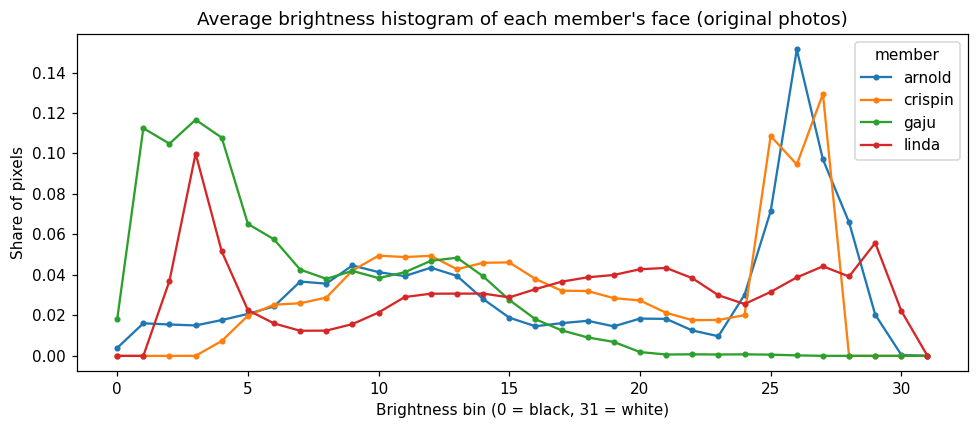

In [44]:
original = df[df["augmentation"] == "original"]
bins = np.arange(32)

fig, ax = plt.subplots(figsize=(9, 4))
for member in members:
    mean_hist = original[original["member_id"] == member][[f"hist_{i}" for i in bins]].mean()
    ax.plot(bins, mean_hist.values, marker="o", markersize=3, label=member)
ax.set_title("Average brightness histogram of each member's face (original photos)")
ax.set_xlabel("Brightness bin (0 = black, 31 = white)")
ax.set_ylabel("Share of pixels")
ax.legend(title="member")
plt.tight_layout()
save_fig(fig, "04_brightness_histograms")
plt.show()

In [45]:

OUTPUT_DIR = Path("/content/drive/MyDrive/MPL_Formative2_Output")
image_features_df.to_csv(OUTPUT_DIR / "image_features.csv", index=False)
print("Saved:", OUTPUT_DIR / "image_features.csv")

Saved: /content/drive/MyDrive/MPL_Formative2_Output/image_features.csv


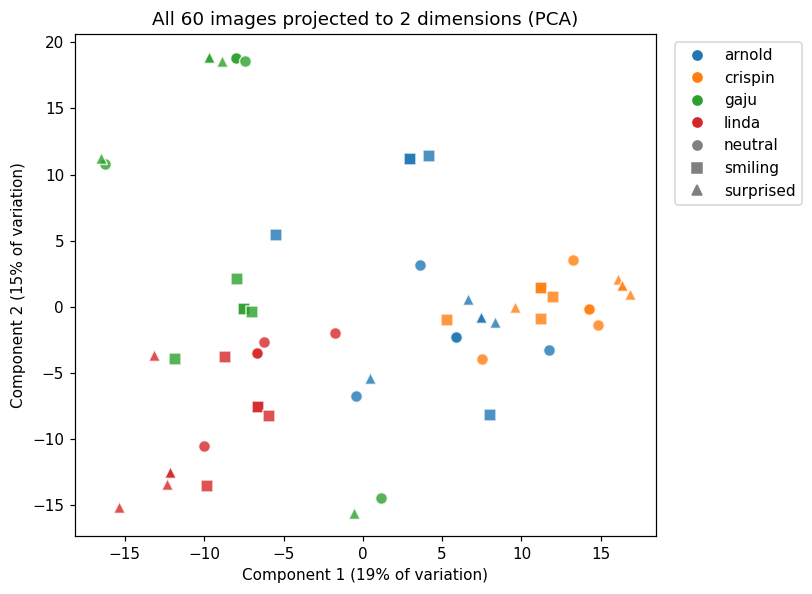

In [46]:
scaled = StandardScaler().fit_transform(df[FEATURE_COLS])
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(scaled)

colours = dict(zip(members, plt.cm.tab10.colors))
markers = {"neutral": "o", "smiling": "s", "surprised": "^"}

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for member in members:
    for expression in EXPRESSIONS:
        mask = ((df["member_id"] == member) & (df["expression"] == expression)).values
        ax.scatter(coords[mask, 0], coords[mask, 1], color=colours[member],
                   marker=markers[expression], s=60, alpha=0.8, edgecolor="white")
ax.set_title("All 60 images projected to 2 dimensions (PCA)")
ax.set_xlabel(f"Component 1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
ax.set_ylabel(f"Component 2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")

member_handles = [plt.Line2D([], [], marker="o", ls="", color=colours[m], label=m) for m in members]
expr_handles = [plt.Line2D([], [], marker=markers[e], ls="", color="grey", label=e) for e in EXPRESSIONS]
ax.legend(handles=member_handles + expr_handles, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_fig(fig, "05_pca_features")
plt.show()

### Face recognition model

In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss
import joblib

def make_models():
    return {
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    }


def evaluate_leave_one_expression_out(model_name):
    """Train on two expressions, test on the third. Returns per-round metrics and every test prediction."""
    rounds, predictions = [], []
    for held_out in EXPRESSIONS:
        train = df[df["expression"] != held_out]
        test = df[(df["expression"] == held_out) & (df["augmentation"] == "original")]

        model = make_models()[model_name]
        model.fit(train[FEATURE_COLS], train["member_id"])
        proba = model.predict_proba(test[FEATURE_COLS])
        pred = model.classes_[proba.argmax(axis=1)]

        rounds.append({
            "model": model_name,
            "test_expression": held_out,
            "accuracy": accuracy_score(test["member_id"], pred),
            "f1": f1_score(test["member_id"], pred, average="weighted", zero_division=0),
            "log_loss": log_loss(test["member_id"], proba, labels=model.classes_),
        })
        predictions.append(pd.DataFrame({
            "true": test["member_id"].values,
            "predicted": pred,
            "confidence": proba.max(axis=1),
            "test_expression": held_out,
        }))
    return pd.DataFrame(rounds), pd.concat(predictions, ignore_index=True)


all_rounds, all_predictions = [], {}
for name in make_models():
    rounds_df, preds_df = evaluate_leave_one_expression_out(name)
    all_rounds.append(rounds_df)
    all_predictions[name] = preds_df

round_results = pd.concat(all_rounds, ignore_index=True)
summary = round_results.groupby("model")[["accuracy", "f1", "log_loss"]].mean().round(3)

print("Results of each round:")
display(round_results.round(3))
print("Average over the 3 rounds:")
display(summary)

best_name = summary.sort_values(["f1", "log_loss"], ascending=[False, True]).index[0]
print("Selected model (highest F1, then lowest log loss):", best_name)

Results of each round:


,model,test_expression,accuracy,f1,log_loss
0,Random Forest,neutral,1.00,1.000,0.593
1,Random Forest,smiling,0.75,0.667,0.719
2,Random Forest,surprised,1.00,1.000,0.464
3,Logistic Regression,neutral,0.75,0.667,0.247
4,Logistic Regression,smiling,1.00,1.000,0.063
5,Logistic Regression,surprised,1.00,1.000,0.041


Average over the 3 rounds:


,accuracy,f1,log_loss
model,,,
Logistic Regression,0.917,0.889,0.117
Random Forest,0.917,0.889,0.592


Selected model (highest F1, then lowest log loss): Logistic Regression


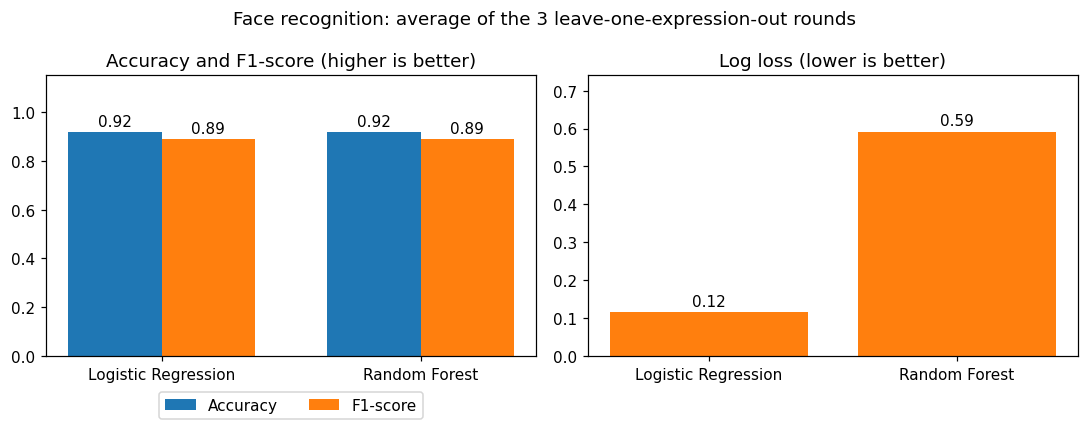

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

x = np.arange(len(summary))
width = 0.36
b1 = axes[0].bar(x - width / 2, summary["accuracy"], width, label="Accuracy")
b2 = axes[0].bar(x + width / 2, summary["f1"], width, label="F1-score")
axes[0].bar_label(b1, fmt="%.2f", padding=2)
axes[0].bar_label(b2, fmt="%.2f", padding=2)
axes[0].set_xticks(x)
axes[0].set_xticklabels(summary.index)
axes[0].set_ylim(0, 1.15)
axes[0].set_title("Accuracy and F1-score (higher is better)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)

b3 = axes[1].bar(summary.index, summary["log_loss"], color="tab:orange")
axes[1].bar_label(b3, fmt="%.2f", padding=2)
axes[1].set_title("Log loss (lower is better)")
axes[1].set_ylim(0, max(summary["log_loss"].max() * 1.25, 0.1))

fig.suptitle("Face recognition: average of the 3 leave-one-expression-out rounds", fontsize=12)
plt.tight_layout()
save_fig(fig, "06_model_metrics")
plt.show()

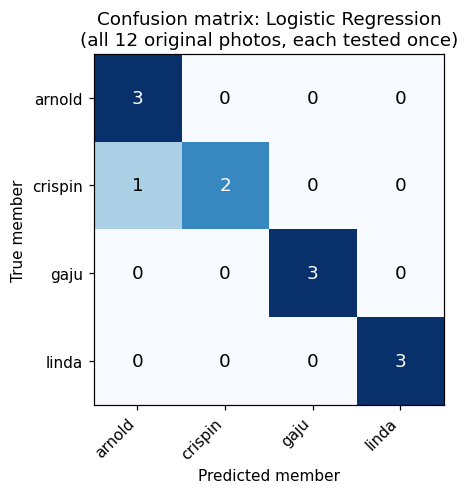

Photos identified wrongly:


,true,predicted,confidence,test_expression
1,crispin,arnold,0.515706,neutral


In [49]:
best_preds = all_predictions[best_name]
cm = confusion_matrix(best_preds["true"], best_preds["predicted"], labels=members)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(members)))
ax.set_yticks(range(len(members)))
ax.set_xticklabels(members, rotation=45, ha="right")
ax.set_yticklabels(members)
ax.set_xlabel("Predicted member")
ax.set_ylabel("True member")
ax.set_title(f"Confusion matrix: {best_name}\n(all 12 original photos, each tested once)")
for i in range(len(members)):
    for j in range(len(members)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
plt.tight_layout()
save_fig(fig, "07_confusion_matrix")
plt.show()

print("Photos identified wrongly:")
wrong = best_preds[best_preds["true"] != best_preds["predicted"]]
display(wrong if len(wrong) else "None: every held-out photo was identified correctly")

### Unauthorised attempts
The model always gives one of the 4 members as an answer, even for a stranger. To block strangers we use the model's confidence (the highest class probability)

In [50]:
# Final model: same choice as above, now trained on ALL 60 images
final_model = make_models()[best_name]
final_model.fit(df[FEATURE_COLS], df["member_id"])


def score_image(model, image_bgr):
    """Return (best_guess, confidence), or (None, 0.0) if no face is found."""
    face, found = crop_face(limit_size(image_bgr))
    if not found:
        return None, 0.0
    x = pd.DataFrame([extract_features(face)])[FEATURE_COLS]
    proba = model.predict_proba(x)[0]
    return str(model.classes_[proba.argmax()]), float(proba.max())


# Outsider photo(s)
outsiders = []
if UNAUTH_DIR.exists():
    for path in sorted(UNAUTH_DIR.iterdir()):
        if path.suffix.lower() in IMG_EXT and cv2.imread(str(path)) is not None:
            guess, conf = score_image(final_model, cv2.imread(str(path)))
            outsiders.append({"file": path.name, "face_found": guess is not None,
                              "closest_member": guess, "confidence": round(conf, 3)})
outsiders_df = pd.DataFrame(outsiders)

if len(outsiders_df):
    print("Outsider photo(s):")
    display(outsiders_df)
else:
    print("No outsider photo found in UNAUTH_DIR. Add one (e.g. unknown_person.jpg) and re-run from this cell.")

# Confidence of team members that were identified correctly (from the leave-one-expression-out test)
correct = best_preds[best_preds["true"] == best_preds["predicted"]]["confidence"]
outsider_conf = outsiders_df.loc[outsiders_df["face_found"], "confidence"].tolist() if len(outsiders_df) else []

if outsider_conf and len(correct) and max(outsider_conf) < correct.min():
    THRESHOLD = round((max(outsider_conf) + correct.min()) / 2, 2)
    print(f"\nThreshold set between the outsider ({max(outsider_conf):.2f}) and the weakest correct member ({correct.min():.2f}): {THRESHOLD}")
else:
    THRESHOLD = 0.5
    print("\nThe confidence of the outsider and of the team members overlap.")
    print("Using the default threshold of 0.5. Mention this limitation in the report.")

Outsider photo(s):


,file,face_found,closest_member,confidence
0,unknown_person.jpg,True,linda,0.496
1,unknown_person1.jpg,True,linda,0.983



The confidence of the outsider and of the team members overlap.
Using the default threshold of 0.5. Mention this limitation in the report.


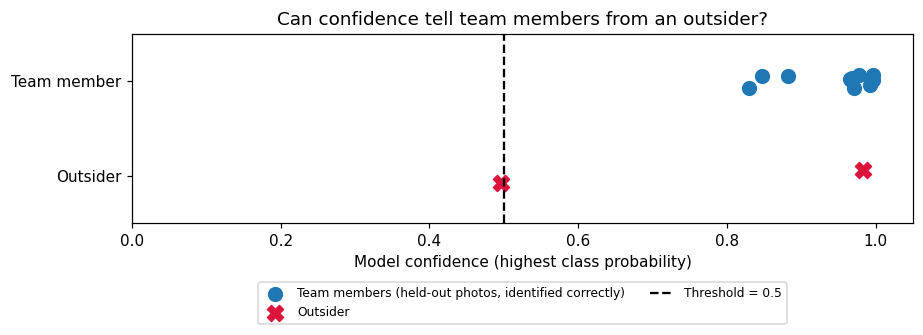

In [51]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8.5, 3.4))

ax.scatter(correct, 1 + rng.uniform(-0.08, 0.08, len(correct)), s=80, color="tab:blue",
           label="Team members (held-out photos, identified correctly)")
if outsider_conf:
    ax.scatter(outsider_conf, 0 + rng.uniform(-0.08, 0.08, len(outsider_conf)), s=110,
               marker="X", color="crimson", label="Outsider")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"Threshold = {THRESHOLD}")

ax.set_yticks([0, 1])
ax.set_yticklabels(["Outsider", "Team member"])
ax.set_ylim(-0.5, 1.5)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Model confidence (highest class probability)")
ax.set_title("Can confidence tell team members from an outsider?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=8)
plt.tight_layout()
save_fig(fig, "08_confidence_threshold")
plt.show()

### Saving the best model create predict_face() for the command-line demo

In [52]:
bundle = {
    "model": final_model,
    "model_name": best_name,
    "feature_cols": FEATURE_COLS,
    "threshold": THRESHOLD,
    "classes": [str(c) for c in final_model.classes_],
}
MODEL_PATH = MODEL_DIR / "face_model.pkl"
joblib.dump(bundle, MODEL_PATH)
print("Model saved:", MODEL_PATH)
print("Model:", best_name, "| members:", bundle["classes"], "| threshold:", THRESHOLD)

Model saved: /content/drive/MyDrive/MPL_Formative2_Output/models/face_model.pkl
Model: Logistic Regression | members: ['arnold', 'crispin', 'gaju', 'linda'] | threshold: 0.5


## Script
- face_auth.py - face check for the CLI demo (generated by the image-processing notebook)
- from face_auth import predict_face
- predict_face("photo.jpg")                 -> "linda" or "unknown"
- predict_face("photo.jpg", details=True)   -> ("linda", 0.83)
- IMPORTANT: limit_size / crop_face / extract_features must stay identical to the notebook,
- otherwise the saved model receives different features than it was trained on.

In [53]:
SCRIPT = r"""
from pathlib import Path

import cv2
import joblib
import numpy as np
import pandas as pd
from skimage import data as skdata
from skimage.feature import Cascade, hog, local_binary_pattern

DEFAULT_MODEL_PATH = Path(__file__).resolve().parent.parent / "models" / "face_model.pkl"

FACE_SIZE = 128
LBP_POINTS, LBP_RADIUS, LBP_GRID = 8, 1, 4
HOG_SETTINGS = dict(orientations=9, pixels_per_cell=(32, 32), cells_per_block=(2, 2), block_norm="L2-Hys")
face_detector = Cascade(skdata.lbp_frontal_face_cascade_filename())
_bundles = {}


def limit_size(img, max_side=1200):
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale >= 1:
        return img
    return cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)


def crop_face(image, size=FACE_SIZE, margin=0.15):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    smallest = max(int(0.04 * min(gray.shape)), 24)
    faces = face_detector.detect_multi_scale(img=gray, scale_factor=1.1, step_ratio=1,
                                             min_size=(smallest, smallest),
                                             max_size=(min(gray.shape), min(gray.shape)))
    if len(faces) == 0:
        return cv2.resize(image, (size, size)), False
    f = max(faces, key=lambda d: d["width"] * d["height"])
    x, y, w, h = f["c"], f["r"], f["width"], f["height"]
    m = int(margin * w)
    x0, y0 = max(x - m, 0), max(y - m, 0)
    x1, y1 = min(x + w + m, image.shape[1]), min(y + h + m, image.shape[0])
    return cv2.resize(image[y0:y1, x0:x1], (size, size)), True


def extract_features(face_bgr):
    gray = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2GRAY)
    feats = {}
    hist = cv2.calcHist([gray], [0], None, [32], [0, 256]).flatten()
    hist = hist / hist.sum()
    for i, v in enumerate(hist):
        feats[f"hist_{i}"] = float(v)
    equalised = cv2.equalizeHist(gray)
    lbp = local_binary_pattern(equalised, LBP_POINTS, LBP_RADIUS, method="uniform")
    cell = FACE_SIZE // LBP_GRID
    for r in range(LBP_GRID):
        for c in range(LBP_GRID):
            patch = lbp[r * cell:(r + 1) * cell, c * cell:(c + 1) * cell]
            h, _ = np.histogram(patch, bins=np.arange(0, LBP_POINTS + 3))
            h = h / h.sum()
            for b, v in enumerate(h):
                feats[f"lbp_{r}{c}_{b}"] = float(v)
    for i, v in enumerate(hog(equalised, **HOG_SETTINGS)):
        feats[f"hog_{i}"] = float(v)
    return feats


def predict_face(image_path, model_path=DEFAULT_MODEL_PATH, details=False):
    key = str(model_path)
    if key not in _bundles:
        _bundles[key] = joblib.load(model_path)
    bundle = _bundles[key]

    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")

    face, found = crop_face(limit_size(image))
    if not found:
        label, confidence = "unknown", 0.0
    else:
        x = pd.DataFrame([extract_features(face)])[bundle["feature_cols"]]
        proba = bundle["model"].predict_proba(x)[0]
        confidence = float(proba.max())
        label = str(bundle["model"].classes_[proba.argmax()]) if confidence >= bundle["threshold"] else "unknown"
        if label != "unknown" and "max_distance" in bundle:
            v = bundle["gate_scaler"].transform(x)
            distance = float(np.sqrt(((bundle["gate_matrix"] - v) ** 2).sum(axis=1)).min())
            if distance > bundle["max_distance"]:
                label = "unknown"
    return (label, confidence) if details else label
"""

SCRIPT_PATH = SCRIPT_DIR / "face_auth.py"
SCRIPT_PATH.write_text(SCRIPT.lstrip("\n"))
print("Script saved:", SCRIPT_PATH)

Script saved: /content/drive/MyDrive/MPL_Formative2_Output/scripts/face_auth.py


In [54]:
# Distance gate: reject faces that are not close to any face we trained on
gate_scaler = StandardScaler().fit(df[FEATURE_COLS])
gate_matrix = gate_scaler.transform(df[FEATURE_COLS])          # the 60 known faces


def nearest_distance(feature_row):
    """Distance from one face to the closest known face (smaller = more similar)."""
    v = gate_scaler.transform(feature_row[FEATURE_COLS])
    return float(np.sqrt(((gate_matrix - v) ** 2).sum(axis=1)).min())


# 1) Distances of team photos that were held out (train on two expressions, test on the third)
genuine_dist = []
for held_out in EXPRESSIONS:
    train = df[df["expression"] != held_out]
    test = df[(df["expression"] == held_out) & (df["augmentation"] == "original")]
    sc = StandardScaler().fit(train[FEATURE_COLS])
    A, B = sc.transform(train[FEATURE_COLS]), sc.transform(test[FEATURE_COLS])
    genuine_dist += list(np.sqrt(((B[:, None, :] - A[None, :, :]) ** 2).sum(axis=2)).min(axis=1))

# 2) Distances of the outsider photos
outsider_dist = {}
for path in sorted(UNAUTH_DIR.iterdir()):
    if path.suffix.lower() in IMG_EXT:
        img = cv2.imread(str(path))
        face, found = crop_face(limit_size(img)) if img is not None else (None, False)
        if found:
            outsider_dist[path.name] = nearest_distance(pd.DataFrame([extract_features(face)]))

print(f"Team photos (held out): distance from {min(genuine_dist):.1f} to {max(genuine_dist):.1f}")
for name, d in outsider_dist.items():
    print(f"Outsider {name}: distance {d:.1f}")

# 3) Switch the gate on only if outsiders are clearly farther than every team photo
if outsider_dist and max(genuine_dist) < min(outsider_dist.values()):
    MAX_DISTANCE = round((max(genuine_dist) + min(outsider_dist.values())) / 2, 1)
    print(f"\nGate ON: faces farther than {MAX_DISTANCE} from every known face are 'unknown'")

    bundle.update({"gate_scaler": gate_scaler, "gate_matrix": gate_matrix, "max_distance": MAX_DISTANCE})
    joblib.dump(bundle, MODEL_PATH)

    old = '        label = str(bundle["model"].classes_[proba.argmax()]) if confidence >= bundle["threshold"] else "unknown"\n'
    new = old + (
        '        if "max_distance" in bundle:\n'
        '            v = bundle["gate_scaler"].transform(x)\n'
        '            if float(np.sqrt(((bundle["gate_matrix"] - v) ** 2).sum(axis=1)).min()) > bundle["max_distance"]:\n'
        '                label = "unknown"\n'
    )
    text = SCRIPT_PATH.read_text()
    if "max_distance" in text:
        print("Script already patched")
    elif old in text:
        SCRIPT_PATH.write_text(text.replace(old, new))
        print("Model and script updated")
    else:
        print("COULD NOT PATCH the script: re-run the SCRIPT cell first, then this cell")
else:
    MAX_DISTANCE = None
    print("\nGate OFF: outsider and team distances overlap (or no outsider found). Model unchanged.")


def notebook_predict(image_bgr):
    """Full notebook-side decision: face found -> confidence -> distance gate."""
    face, found = crop_face(limit_size(image_bgr))
    if not found:
        return "unknown"
    feats = pd.DataFrame([extract_features(face)])[FEATURE_COLS]
    proba = final_model.predict_proba(feats)[0]
    if proba.max() < THRESHOLD:
        return "unknown"
    if MAX_DISTANCE is not None and nearest_distance(feats) > MAX_DISTANCE:
        return "unknown"
    return str(final_model.classes_[proba.argmax()])

Team photos (held out): distance from 17.7 to 30.9
Outsider unknown_person.jpg: distance 54.0
Outsider unknown_person1.jpg: distance 33.3

Gate ON: faces farther than 32.1 from every known face are 'unknown'
Script already patched


In [55]:
print(SCRIPT_PATH)
for line in SCRIPT_PATH.read_text().splitlines():
    if "ascade" in line:
        print(line)

/content/drive/MyDrive/MPL_Formative2_Output/scripts/face_auth.py
from skimage.feature import Cascade, hog, local_binary_pattern
face_detector = Cascade(skdata.lbp_frontal_face_cascade_filename())


In [57]:
import importlib.util
import sys

sys.dont_write_bytecode = True
spec = importlib.util.spec_from_file_location("face_auth", SCRIPT_PATH)
face_auth = importlib.util.module_from_spec(spec)
spec.loader.exec_module(face_auth)

test_files = [(r["member_id"], r["path"], "member") for r in records] + \
             [("outsider", UNAUTH_DIR / row["file"], "outsider") for row in outsiders]

check_rows, all_match = [], True
for true_label, path, test_type in test_files:
    image = cv2.imread(str(path))
    guess, conf = score_image(final_model, image)
    notebook_answer = notebook_predict(image)
    script_answer = face_auth.predict_face(path)
    all_match &= (notebook_answer == script_answer)

    check_rows.append({
        "photo": Path(path).name,
        "type": test_type,
        "expected": true_label,
        "notebook": notebook_answer,
        "script": script_answer,
        "model_confidence": round(conf, 2) if conf is not None else 0.0,
    })

print("Notebook and prediction script agree on every checked photo:", all_match)
print(
    "Note: member photos in this table were used to train the final model. "
    "This is a consistency check between implementations, not an independent accuracy test."
)
display(pd.DataFrame(check_rows))

Notebook and prediction script agree on every checked photo: True
Note: member photos in this table were used to train the final model. This is a consistency check between implementations, not an independent accuracy test.


,photo,type,expected,notebook,script,model_confidence
0,arnold_neutralface.jpeg,member,arnold,arnold,arnold,1.00
1,arnold_smilingface.jpeg,member,arnold,arnold,arnold,1.00
2,arnold_surprisedface.jpeg,member,arnold,arnold,arnold,1.00
3,crispin_neutralface.JPG,member,crispin,crispin,crispin,1.00
4,crispin_smilingface.JPG,member,crispin,crispin,crispin,1.00
5,crispin_surprisedface.JPG,member,crispin,crispin,crispin,1.00
6,gaju_neutralface.jpg,member,gaju,gaju,gaju,1.00
7,gaju_smilingface.jpg,member,gaju,gaju,gaju,1.00
8,gaju_suprisedface.jpg,member,gaju,gaju,gaju,1.00
9,linda_neutralface.jpg,member,linda,linda,linda,1.00


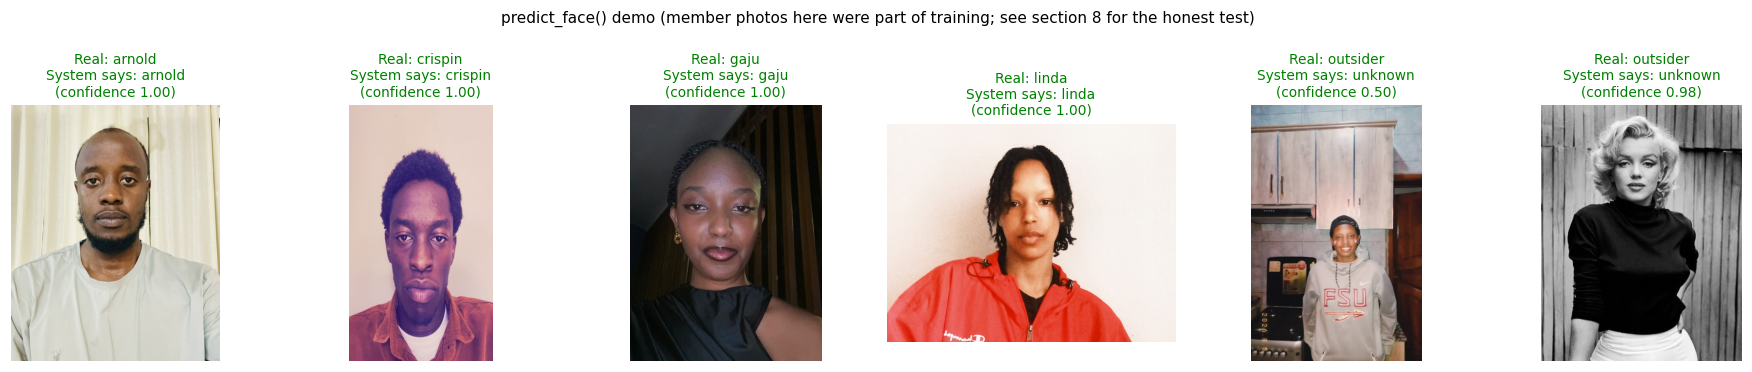

In [58]:
# Demo preview: what the face check says for one photo per member and for the outsider(s)
preview = [(m, lookup[(m, "neutral")]["path"] if (m, "neutral") in lookup
            else next(r["path"] for r in records if r["member_id"] == m)) for m in members]
preview += [("outsider", UNAUTH_DIR / row["file"]) for row in outsiders]

fig, axes = plt.subplots(1, len(preview), figsize=(2.8 * len(preview), 3.4), squeeze=False)
for ax, (who, path) in zip(axes[0], preview):
    label, conf = face_auth.predict_face(path, details=True)
    ax.imshow(cv2.cvtColor(limit_size(cv2.imread(str(path))), cv2.COLOR_BGR2RGB))
    ok = (label == who) or (who == "outsider" and label == "unknown")
    ax.set_title(f"Real: {who}\nSystem says: {label}\n(confidence {conf:.2f})",
                 fontsize=9, color="green" if ok else "red")
    ax.axis("off")

fig.suptitle("predict_face() demo (member photos here were part of training; see section 8 for the honest test)",
             fontsize=10)
plt.tight_layout()
save_fig(fig, "09_predict_face_demo")
plt.show()

In [59]:
print("Files created in", OUTPUT_DIR, "\n")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file() and "processed_faces" not in p.parts:
        print(f"{p.relative_to(OUTPUT_DIR)}  ({p.stat().st_size / 1024:.0f} KB)")
n_proc = sum(1 for _ in PROCESSED_DIR.rglob("*.jpg"))
print(f"processed_faces/  ({n_proc} images)")

Files created in /content/drive/MyDrive/MPL_Formative2_Output 

figures/01_original_photos.png  (1549 KB)
figures/02_cropped_faces.png  (1362 KB)
figures/03_augmentations.png  (1443 KB)
figures/04_brightness_histograms.png  (101 KB)
figures/05_pca_features.png  (51 KB)
figures/06_model_metrics.png  (47 KB)
figures/07_confusion_matrix.png  (36 KB)
figures/08_confidence_threshold.png  (35 KB)
figures/09_predict_face_demo.png  (577 KB)
image_features.csv  (522 KB)
models/face_model.pkl  (300 KB)
scripts/face_auth.py  (3 KB)
processed_faces/  (60 images)


### Limitation
- The dataset contains a limited number of images and facial expressions, which may affect how well the models generalize to new images.
- Lighting, facial angles, image quality, and variations in facial expressions may influence feature extraction and prediction accuracy.
- The face authentication system is evaluated using a limited set of known member images; therefore, its ability to reliably identify completely unseen individuals requires further testing.
- The distance threshold used to distinguish registered members from unknown individuals may need further tuning using a larger and more diverse dataset.
- The system is intended as an experimental demonstration and should not be used as a standalone real-world authentication system.